In [3]:
import os
# Force TensorFlow to use deterministic GPU algorithms
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

import tensorflow as tf
# Set random seeds for Python, NumPy, and TensorFlow
tf.keras.utils.set_random_seed(42)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# ML models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Evaluation
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

import warnings
warnings.filterwarnings('ignore')

# **Data**

In [4]:
!pip install -q kagglehub scikit-image

In [5]:
import kagglehub
dataset_path=kagglehub.dataset_download("abdelghaniaaba/wildfire-prediction-dataset")
print(dataset_path)
print(os.listdir(dataset_path))

Using Colab cache for faster access to the 'wildfire-prediction-dataset' dataset.
/kaggle/input/wildfire-prediction-dataset
['valid', 'test', 'train']


In [6]:
classes=['nowildfire','wildfire']
for folder in ['train','valid','test']:
  print('\n',folder)
  for category in classes:
    path=os.path.join(dataset_path,folder,category)
    print(category,":=",len(os.listdir(path)))


 train
nowildfire := 14500
wildfire := 15750

 valid
nowildfire := 2820
wildfire := 3480

 test
nowildfire := 2820
wildfire := 3480


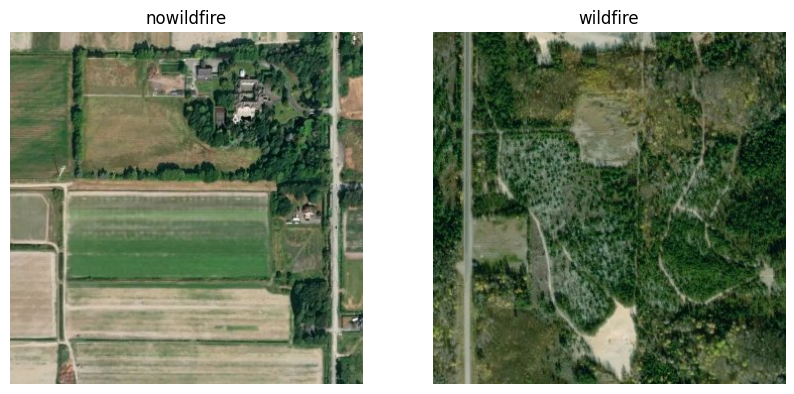

In [7]:
plt.figure(figsize=(10, 5))
for i, category in enumerate(classes):
    path = os.path.join(dataset_path, 'train', category)
    image_name = os.listdir(path)[0]
    #concatenate multiple path segments (directories, subdirectories, and filenames) into a single path string
    image_path = os.path.join(path, image_name)
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 2, i+1)
    plt.imshow(image)
    plt.title(category)
    plt.axis('off')

plt.show()

 We will use <br> **No Wildfire=0 <br> Wildfire=1**

In [8]:
class_2_label={
    'nowildfire':0,
    'wildfire':1
}

# **Data Frame**

In [9]:
def dataframe(folder):
  image_paths=[]
  labels=[]
  for category in classes:
    path=os.path.join(dataset_path,folder,category)
    for image_name in os.listdir(path):
      image_paths.append(os.path.join(path,image_name))
      labels.append(class_2_label[category])
  df=pd.DataFrame({
      'image_path':image_paths,
      'label':labels
  })
  return df

**Creating Dataframe from Data**<br>
To keep the notebook light enough to run in one go, only a *stratified random fraction* of each split is used (class ratio is preserved). Change `TRAIN_FRAC`, `VAL_FRAC`, `TEST_FRAC` in the next cell; set them to `1.0` to use the full dataset.

In [10]:
# ---------- Dataset size control ----------
# Fraction of each split to keep (1.0 = full data).
# Full data: train 30250, valid 6300, test 6300 images.
TRAIN_FRAC = 0.4   # ~12,100 images
VAL_FRAC   = 1   # ~6300 images
TEST_FRAC  = 1   # ~6300 images

def subsample(df, frac, seed=42):
  if frac >= 1.0:
    return df
  # sample the same fraction inside each class, so the class ratio stays the same
  df = df.groupby('label', group_keys=False).sample(frac=frac, random_state=seed)
  # shuffle the rows and reset the index
  return df.sample(frac=1.0, random_state=seed).reset_index(drop=True)

train_df=subsample(dataframe('train'), TRAIN_FRAC)
valid_df=subsample(dataframe('valid'), VAL_FRAC)
test_df=subsample(dataframe('test'), TEST_FRAC)

print(train_df.shape)
print(valid_df.shape)
print(test_df.shape)
display(train_df)
# print(train_df.iloc[0][1])
print("\nTraining class distribution:")
print(train_df['label'].value_counts())

print("\nValidation class distribution:")
print(valid_df['label'].value_counts())

print("\nTesting class distribution:")
print(test_df['label'].value_counts())

(12100, 2)
(6300, 2)
(6300, 2)


,image_path,label
0,/kaggle/input/wildfire-prediction-dataset/trai...,1
1,/kaggle/input/wildfire-prediction-dataset/trai...,0
2,/kaggle/input/wildfire-prediction-dataset/trai...,0
3,/kaggle/input/wildfire-prediction-dataset/trai...,1
4,/kaggle/input/wildfire-prediction-dataset/trai...,0
...,...,...
12095,/kaggle/input/wildfire-prediction-dataset/trai...,1
12096,/kaggle/input/wildfire-prediction-dataset/trai...,0
12097,/kaggle/input/wildfire-prediction-dataset/trai...,0
12098,/kaggle/input/wildfire-prediction-dataset/trai...,0



Training class distribution:
label
1    6300
0    5800
Name: count, dtype: int64

Validation class distribution:
label
1    3480
0    2820
Name: count, dtype: int64

Testing class distribution:
label
1    3480
0    2820
Name: count, dtype: int64


**Image Preprocessing**

In [11]:
def preprocess_image(image_path):
    image = cv2.imread(image_path)
    image = cv2.resize(image, (128, 128))
    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB)
    image = image / 255.0
    return image

**will allocate the feature matrix beforehand and fill it one image at a time.**

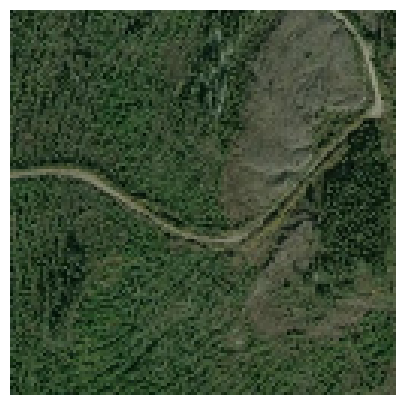

In [12]:
plt.figure(figsize=(10,5))
image_path=train_df.iloc[0]['image_path']
image=preprocess_image(image_path)
plt.imshow(image)
plt.axis('off')
plt.show()

**Extract HOG, LBP and colour features**

In [13]:
from skimage.feature import hog
from skimage.feature import local_binary_pattern

In [14]:
def extract_features(image_path):
  image=preprocess_image(image_path)

  #Convert to grayscale
  gray=cv2.cvtColor(
      (image*255).astype(np.uint8),
      cv2.COLOR_RGB2GRAY)

  #HOG feature
  #hog_features is a 1D array of size 1764.
  hog_features=hog(
      gray,
      orientations=9,
      pixels_per_cell=(16,16),
      cells_per_block=(2,2),
      block_norm='L2-Hys')

  #LBP features
  #lbp_hist is a 1D array of size 10.
  lbp=local_binary_pattern(
      gray,
      P=8,
      R=1,
      method='uniform')
  lbp = local_binary_pattern(
        gray,
        P=8,
        R=1,
        method='uniform'
    )
  lbp_hist, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(0, 11),
        density=True
    )

  # Colour histogram
  #color_features is a list of three 1D arrays (each of size 8).
  color_features = []
  for channel in range(3):
    hist,_=np.histogram(
        image[:,:,channel],
        bins=8,
        range=(0,1),
        density=True)
    color_features.append(hist)

  # Flatten color_features into a 1D array
  color_features_flat = np.concatenate(color_features)

  #Combine all features
  features=np.concatenate([
      hog_features,
      lbp_hist,
      color_features_flat])
  return features.astype(np.float32)

**Let update for all images**

In [15]:
from tqdm import tqdm  # it is a progress bar,
#provides instant visual feedback on long-running tasks without slowing down the code

def create_features(df):
  '''Total Feature Vector(1798 Dim)=[f_Hog || f_LBP || f_Color ]'''
  X=np.empty(
      (len(df),1798),
      dtype=np.float32)
  y=df['label'].to_numpy(dtype=np.int32)

  for i in tqdm(range(len(df))):
    image_path=df.iloc[i]['image_path']
    X[i]=extract_features(image_path)
  return X,y


**Converting Train-Validation-Test data to this format**

In [16]:
X_train, y_train = create_features(train_df)
X_val, y_val = create_features(valid_df)
X_test, y_test = create_features(test_df)


100%|██████████| 6300/6300 [03:12<00:00, 32.69it/s]


In [17]:
print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)

print("Validation features:", X_val.shape)
print("Validation labels:", y_val.shape)

print("Testing features:", X_test.shape)
print("Testing labels:", y_test.shape)

Training features: (12100, 1798)
Training labels: (12100,)
Validation features: (6300, 1798)
Validation labels: (6300,)
Testing features: (6300, 1798)
Testing labels: (6300,)


# **Approach 1: Traditional ML Models**

In [18]:
from sklearn.svm import LinearSVC

In [19]:
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(
            max_iter=1000,
            solver='saga'))]),

    'SVM': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearSVC(
            C=1.0,
            max_iter=5000,
            random_state=42
        ))]),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    )}


**Training**

In [20]:
import time

In [21]:
results=[]
trained_models={}
for name ,model in models.items():
  print("\nTraining teh model :",name)
  start=time.time()
  model.fit(X_train,y_train)
  end=time.time()
  y_pred=model.predict(X_val)
  trained_models[name]=model
  results.append({
      'Model': name,
      'Accuracy': accuracy_score(y_val,y_pred),
      'Precision': precision_score(y_val,y_pred),
      'Recall': recall_score(y_val,y_pred),
      'F1 Score': f1_score(y_val,y_pred),
      'Training Time': end-start
  })



Training teh model : Logistic Regression

Training teh model : SVM

Training teh model : Random Forest

Training teh model : Decision Tree


*Results*

In [22]:
display(pd.DataFrame(results))

,Model,Accuracy,Precision,Recall,F1 Score,Training Time
0,Logistic Regression,0.899683,0.919317,0.897126,0.908086,437.632664
1,SVM,0.876825,0.906739,0.866092,0.885949,95.722336
2,Random Forest,0.938571,0.954987,0.932759,0.943742,84.035051
3,Decision Tree,0.906032,0.932335,0.894828,0.913196,97.452381


**Since LinearSVC does not directly provide class probabilities, we will use hard voting instead of soft voting.**

In [24]:
ensemble=VotingClassifier(
    estimators=[
        ('logistic_regression', models['Logistic Regression']),
        ('svm', models['SVM']),
        ('random_forest', models['Random Forest']),
    ],
    voting='hard'
)

**Prediction**

In [25]:
start = time.time()
ensemble.fit(X_train, y_train)
end = time.time()

y_pred = ensemble.predict(X_val)
ensemble_acc = accuracy_score(y_val, y_pred)
ensemble_precision = precision_score(y_val, y_pred)
ensemble_recall = recall_score(y_val, y_pred)
ensemble_f1 = f1_score(y_val, y_pred)

results.append({
    'Model': 'Custom Ensemble',
    'Accuracy': ensemble_acc,
    'Precision': ensemble_precision,
    'Recall': ensemble_recall,
    'F1 Score': ensemble_f1,
    'Training Time': end - start
})
print("Ensemble Accuracy:", ensemble_acc)
print("Ensemble F1 Score:", ensemble_f1)

Ensemble Accuracy: 0.9053968253968254
Ensemble F1 Score: 0.9131701631701632


In [26]:
results_df=pd.DataFrame(results)
results_df=results_df.sort_values(
    by='Accuracy',
    ascending=False
)
display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score,Training Time
2,Random Forest,0.938571,0.954987,0.932759,0.943742,84.035051
3,Decision Tree,0.906032,0.932335,0.894828,0.913196,97.452381
4,Custom Ensemble,0.905397,0.926123,0.900575,0.913170,603.181938
0,Logistic Regression,0.899683,0.919317,0.897126,0.908086,437.632664
1,SVM,0.876825,0.906739,0.866092,0.885949,95.722336


**Comparison the model**

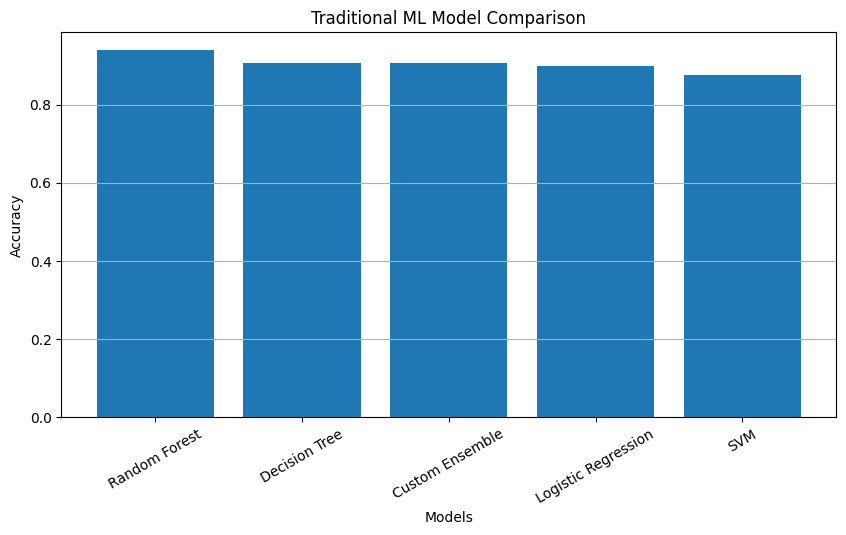

In [27]:
plt.figure(figsize=(10, 5))
plt.bar(
    results_df['Model'],
    results_df['Accuracy']
)

plt.xlabel("Models")
plt.ylabel("Accuracy")

plt.title("Traditional ML Model Comparison")
plt.xticks(rotation=30)
plt.grid(axis='y')

plt.show()

# **CNN Approch**

**Preparing The tensorflow dataset**

In [28]:
IMG_SIZE = (128, 128)
Batch_size = 32

def create_tf_dataset(df, shuffle=False):
  image_paths = df['image_path'].values
  labels = df['label'].values.astype(np.float32)
  dataset = tf.data.Dataset.from_tensor_slices((image_paths, labels))

  # Shuffle only the (path,label) pairs, BEFORE the images are decoded.
  if shuffle:
    dataset = dataset.shuffle(buffer_size=len(df), seed=42)

  def _py_load_image(image_path, label):
    # Decode the byte tensor back to string
    path_str = image_path.numpy().decode('utf-8')
    try:
        # Read using OpenCV, which gracefully handles corrupted/truncated JPEGs
        img = cv2.imread(path_str)
        if img is None:
            # Fallback placeholder if the image is completely unreadable
            img = np.zeros((IMG_SIZE[0], IMG_SIZE[1], 3), dtype=np.float32)
        else:
            img = cv2.resize(img, IMG_SIZE)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = img.astype(np.float32) / 255.0
    except Exception:
        img = np.zeros((IMG_SIZE[0], IMG_SIZE[1], 3), dtype=np.float32)

    label_arr = np.array([label], dtype=np.float32)
    return img, label_arr

  def load_image(image_path, label):
    img, lbl = tf.py_function(
        _py_load_image,
        inp=[image_path, label],
        Tout=[tf.float32, tf.float32]
    )
    img.set_shape((IMG_SIZE[0], IMG_SIZE[1], 3))
    lbl.set_shape((1,))
    return img, lbl

  dataset = dataset.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
  dataset = dataset.batch(Batch_size)
  dataset = dataset.prefetch(tf.data.AUTOTUNE)
  return dataset

**Train-eval-test**

In [29]:
train_ds = create_tf_dataset(train_df,shuffle=True)
train_eval_ds = create_tf_dataset(train_df)
#we will later extrat CNN features from it ,so we need to maintain the
#correspondence between each feature vector and its label. That's why we are not shuffling it
valid_ds = create_tf_dataset(valid_df)
test_ds = create_tf_dataset(test_df)

***Main CNN Architecture***

In [30]:
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Input, Conv2D, MaxPooling2D, BatchNormalization, GlobalAveragePooling2D, Dropout

cnn = Sequential()
cnn.add(Input(shape=(128, 128, 3)))  #explicit input layer (needed later for the feature extractor)
cnn.add(Conv2D(
    32, #number of filters
    (3, 3),  #filter matrix size
    padding='same',
    #adding #of padding such that input height and width are same as input's ,
    #here 1-padding,stride=default which is 1
    activation='relu'))
cnn.add(MaxPooling2D((2, 2)))  #using maxpooling
cnn.add(BatchNormalization())  # normalizes (rescales and recenters) the outputs of a previous layer
#after using filters output will be (128,128,3)--->maxpooling--->output shape=(64,64,32)

cnn.add(Conv2D(
    64,   #filters
    (3, 3),
    padding='same',
    activation='relu'))
cnn.add(MaxPooling2D((2, 2)))
cnn.add(BatchNormalization())
#after using filters output will be (64,64,64)--->maxpooling--->output shape=(32,32,64)

cnn.add(Conv2D(
    128,
    (3, 3),
    padding='same',
    activation='relu'))
cnn.add(MaxPooling2D((2, 2)))
#after using filters output will be (32,32,128)--->maxpooling--->output shape=(16,16,128)

cnn.add(GlobalAveragePooling2D())
#for each channel, it will take average of all matrix element .
#so output shape will be (128,1)

#we will use it as input layer inside normal perceptron model
cnn.add(Dense(
    128,
    activation='relu',
    name='feature_layer'))
    #Assigns a custom identifier string so we can easily extract this 128-dimensional embedding vector later
cnn.add(Dropout(0.3))
#hidden layer's node no is 128+1(bias term)
#total 128*129 parameters

cnn.add(Dense(
    1,
    activation='sigmoid'
))
#output layer

In [31]:
cnn.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
cnn.summary

<bound method Model.summary of <Sequential name=sequential, built=True>>

**Training CNN on all images**

In [48]:
from tensorflow.keras.callbacks import EarlyStopping
import time

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

start = time.time()

history = cnn.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=10,
    callbacks=[early_stopping]
)

cnn_training_time = time.time() - start

print("CNN Training Time:", cnn_training_time)

Epoch 1/10
379/379 ━━━━━━━━━━━━━━━━━━━━ 144s 380ms/step - accuracy: 0.9550 - loss: 0.1225 - val_accuracy: 0.9470 - val_loss: 0.1425
Epoch 2/10
379/379 ━━━━━━━━━━━━━━━━━━━━ 122s 321ms/step - accuracy: 0.9570 - loss: 0.1175 - val_accuracy: 0.9143 - val_loss: 0.1995
Epoch 3/10
379/379 ━━━━━━━━━━━━━━━━━━━━ 120s 316ms/step - accuracy: 0.9605 - loss: 0.1087 - val_accuracy: 0.9600 - val_loss: 0.1036
Epoch 4/10
379/379 ━━━━━━━━━━━━━━━━━━━━ 119s 315ms/step - accuracy: 0.9640 - loss: 0.0994 - val_accuracy: 0.9594 - val_loss: 0.1046
Epoch 5/10
379/379 ━━━━━━━━━━━━━━━━━━━━ 120s 316ms/step - accuracy: 0.9656 - loss: 0.0959 - val_accuracy: 0.7529 - val_loss: 0.5304
Epoch 6/10
379/379 ━━━━━━━━━━━━━━━━━━━━ 119s 314ms/step - accuracy: 0.9655 - loss: 0.0920 - val_accuracy: 0.9133 - val_loss: 0.2206
CNN Training Time: 743.6447238922119


***Plottings***

*Accuracy Plot*

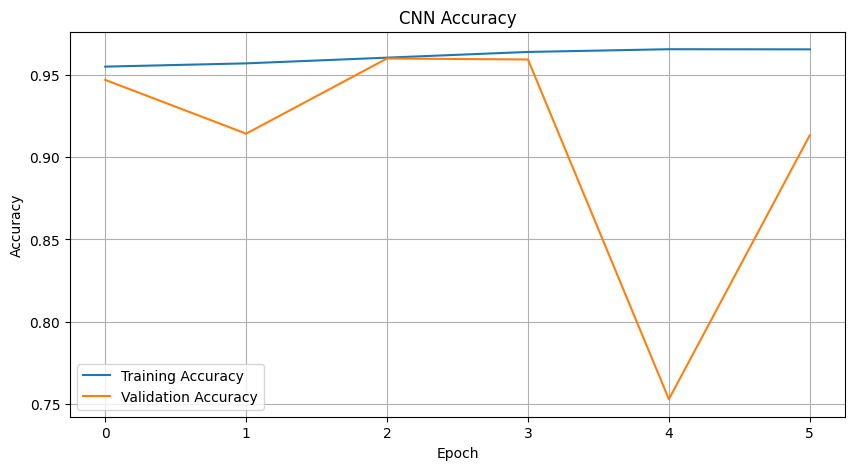

In [49]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy')

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.title('CNN Accuracy')
plt.legend()
plt.grid(True)

plt.show()

*Loss Plot*

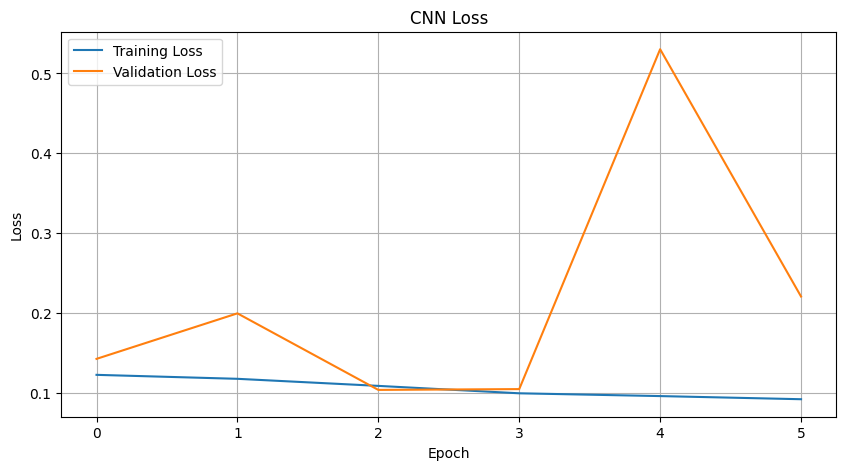

In [50]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss')

plt.plot(
    history.history['val_loss'],
    label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.title('CNN Loss')
plt.legend()
plt.grid(True)

plt.show()

# **CNN+Traditional ML**<br> Here, we will extract the 128-dimensional features from the CNN and give them to SVM and Logistic Regression.


**Feature Extractor**

In [51]:
feature_extractor=Model(inputs=cnn.inputs,
                        outputs=cnn.get_layer('feature_layer').output)
feature_extractor.summary()

Model: "functional_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ feature_layer (Dense)           │ (None, 128)            │        16,512 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,144 (430.25 KB)

 Trainable params: 109,952 (429.50 KB)

 Non-trainable params: 192 (768.00 B)

**Extract CNN features**

In [52]:
def extract_cnn_features(dataset):
  X=[]
  y=[]
  for images,labels in tqdm(dataset):
    features=feature_extractor.predict(images,verbose=0)
    #convert raw images into compact numerical feature vectors
    X.append(features.astype(np.float32))
    y.append(labels.numpy())
  X=np.concatenate(X)
  y=np.concatenate(y).ravel().astype(np.int32)
  # Joins all label batches along axis=0 into a single array of length N
  #ravel for flattens any extra singleton dimension
  return X,y

*Train-Val-Test*


In [53]:
X_train_cnn, y_train_cnn = extract_cnn_features(train_eval_ds)
print("Training:", X_train_cnn.shape)

X_val_cnn, y_val_cnn = extract_cnn_features(valid_ds)
print("Validation:", X_val_cnn.shape)

X_test_cnn, y_test_cnn = extract_cnn_features(test_ds)
print("Testing:", X_test_cnn.shape)

100%|██████████| 379/379 [01:44<00:00,  3.62it/s]


Training: (12100, 128)


100%|██████████| 197/197 [00:54<00:00,  3.63it/s]


Validation: (6300, 128)


100%|██████████| 197/197 [00:59<00:00,  3.32it/s]

Testing: (6300, 128)


**CNN+SVM**

In [54]:
cnn_svm=Pipeline([
    ('scaler',StandardScaler()),
    ('model',LinearSVC(C=1.0,max_iter=5000,random_state=42))
])

start=time.time()
cnn_svm.fit(X_train_cnn,y_train_cnn)
cnn_svm_training_time=time.time()-start

y_pred_svm=cnn_svm.predict(X_val_cnn)
print("CNN + SVM Accuracy:",accuracy_score(y_val_cnn, y_pred_svm))
print("Training Time:", cnn_svm_training_time)

CNN + SVM Accuracy: 0.9692063492063492
Training Time: 0.5721962451934814


**CNN+Logistic-Regression**

In [55]:
cnn_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        max_iter=1000,
        solver='saga'))
])

start = time.time()
cnn_lr.fit(X_train_cnn,y_train_cnn)
cnn_lr_training_time = time.time() - start

y_pred_lr = cnn_lr.predict(X_val_cnn)

print("CNN + Logistic Regression Accuracy:",accuracy_score(y_val_cnn, y_pred_lr))
print("Training Time:", cnn_lr_training_time)

CNN + Logistic Regression Accuracy: 0.9658730158730159
Training Time: 33.99269199371338


# **Final Comparison before test case**

In [56]:
cnn_val_prob = cnn.predict(valid_ds)

cnn_val_pred = (cnn_val_prob >= 0.5).astype(int).ravel()

cnn_val_accuracy = accuracy_score(
    y_val_cnn,
    cnn_val_pred)

cnn_val_f1 = f1_score(
    y_val_cnn,
    cnn_val_pred)

print("CNN Accuracy:", cnn_val_accuracy)
print("CNN F1 Score:", cnn_val_f1)

197/197 ━━━━━━━━━━━━━━━━━━━━ 37s 189ms/step
CNN Accuracy: 0.96
CNN F1 Score: 0.964


**Adding CNN,CNN+SVM,CNN+Logistic result**

In [65]:
# Prevent duplicates by filtering out previous records of the same models if they exist
models_to_add = ['CNN', 'CNN + SVM', 'CNN + Logistic Regression']
results = [r for r in results if r['Model'] not in models_to_add]

results.append({
    'Model': 'CNN',
    'Accuracy': cnn_val_accuracy,
    'Precision': precision_score(y_val_cnn, cnn_val_pred),
    'Recall': recall_score(y_val_cnn, cnn_val_pred),
    'F1 Score': cnn_val_f1,
    'Training Time': cnn_training_time
})

results.append({
    'Model': 'CNN + SVM',
    'Accuracy': accuracy_score(y_val_cnn, y_pred_svm),
    'Precision': precision_score(y_val_cnn, y_pred_svm),
    'Recall': recall_score(y_val_cnn, y_pred_svm),
    'F1 Score': f1_score(y_val_cnn, y_pred_svm),
    'Training Time': cnn_svm_training_time
})

results.append({
    'Model': 'CNN + Logistic Regression',
    'Accuracy': accuracy_score(y_val_cnn, y_pred_lr),
    'Precision': precision_score(y_val_cnn, y_pred_lr),
    'Recall': recall_score(y_val_cnn, y_pred_lr),
    'F1 Score': f1_score(y_val_cnn, y_pred_lr),
    'Training Time': cnn_lr_training_time
})

**Comparison**

In [67]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='Accuracy',
    ascending=False
)
display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score,Training Time
6,CNN + SVM,0.969206,0.976785,0.967241,0.971990,0.572196
7,CNN + Logistic Regression,0.965873,0.973875,0.964080,0.968953,33.992692
5,CNN,0.960000,0.958523,0.969540,0.964000,743.644724
2,Random Forest,0.938571,0.954987,0.932759,0.943742,84.035051
3,Decision Tree,0.906032,0.932335,0.894828,0.913196,97.452381
4,Custom Ensemble,0.905397,0.926123,0.900575,0.913170,603.181938
0,Logistic Regression,0.899683,0.919317,0.897126,0.908086,437.632664
1,SVM,0.876825,0.906739,0.866092,0.885949,95.722336


**Accuracy Comparison**

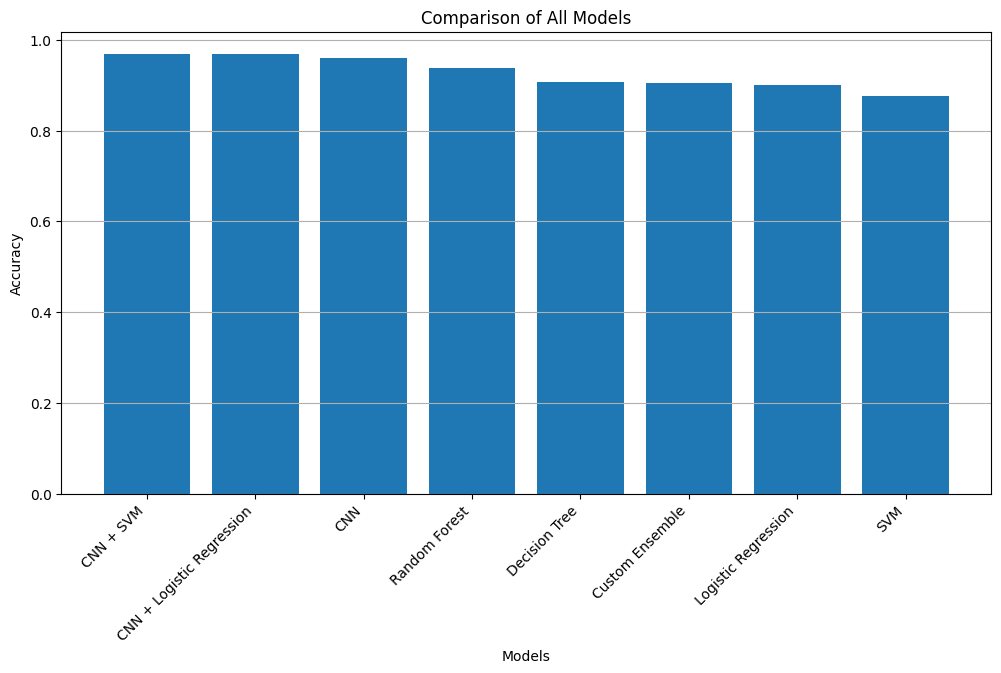

In [59]:
plt.figure(figsize=(12, 6))
plt.bar(
    results_df['Model'],
    results_df['Accuracy']
)

plt.xlabel('Models')
plt.ylabel('Accuracy')

plt.title('Comparison of All Models')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')

plt.show()

**F1 Comparison**

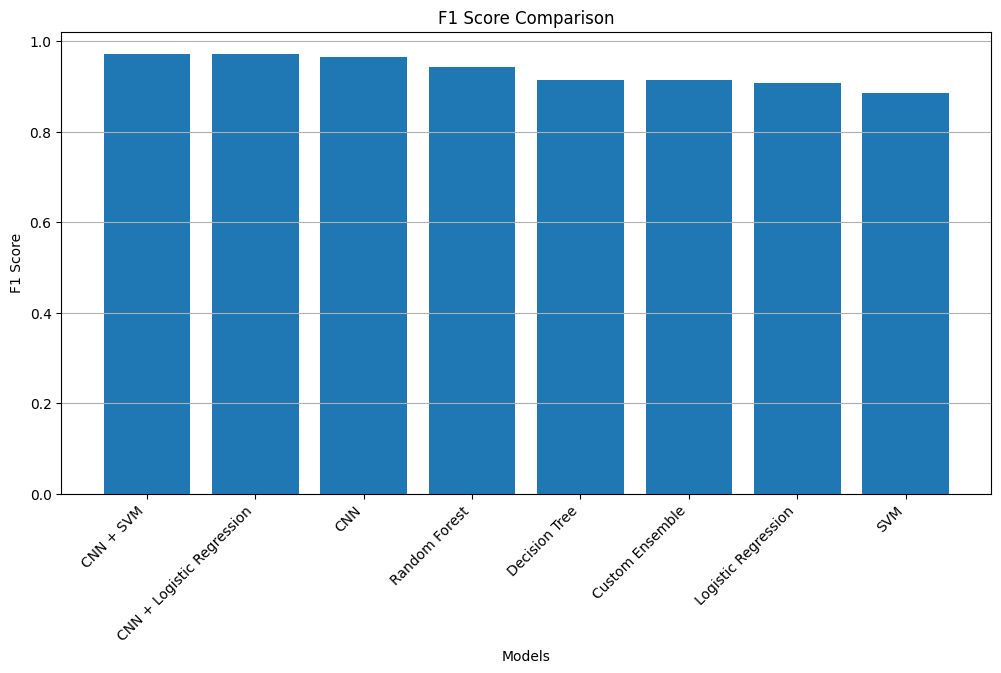

In [60]:
plt.figure(figsize=(12, 6))
plt.bar(
    results_df['Model'],
    results_df['F1 Score']
)

plt.xlabel('Models')
plt.ylabel('F1 Score')

plt.title('F1 Score Comparison')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')

plt.show()

# **Final Test Evaluation**

**Evaluating all models**

In [61]:
test_results = []

# Traditional ML models
for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    test_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred)})

# Voting Ensemble
y_pred = ensemble.predict(X_test)
test_results.append({
    'Model': 'Custom Ensemble',
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1 Score': f1_score(y_test, y_pred)})

# CNN
cnn_test_prob = cnn.predict(test_ds)
cnn_test_pred = (
    cnn_test_prob >= 0.5
).astype(int).ravel()
test_results.append({
    'Model': 'CNN',
    'Accuracy': accuracy_score(y_test_cnn, cnn_test_pred),
    'Precision': precision_score(y_test_cnn, cnn_test_pred),
    'Recall': recall_score(y_test_cnn, cnn_test_pred),
    'F1 Score': f1_score(y_test_cnn, cnn_test_pred)
})

# CNN + SVM
y_pred = cnn_svm.predict(X_test_cnn)
test_results.append({
    'Model': 'CNN + SVM',
    'Accuracy': accuracy_score(y_test_cnn, y_pred),
    'Precision': precision_score(y_test_cnn, y_pred),
    'Recall': recall_score(y_test_cnn, y_pred),
    'F1 Score': f1_score(y_test_cnn, y_pred)
})

# CNN + Logistic Regression
y_pred = cnn_lr.predict(X_test_cnn)
test_results.append({
    'Model': 'CNN + Logistic Regression',
    'Accuracy': accuracy_score(y_test_cnn, y_pred),
    'Precision': precision_score(y_test_cnn, y_pred),
    'Recall': recall_score(y_test_cnn, y_pred),
    'F1 Score': f1_score(y_test_cnn, y_pred)
})

197/197 ━━━━━━━━━━━━━━━━━━━━ 37s 189ms/step


**Final Results**

In [62]:
final_results = pd.DataFrame(test_results)

final_results = final_results.sort_values(
    by='F1 Score',
    ascending=False
)

display(final_results)

,Model,Accuracy,Precision,Recall,F1 Score
6,CNN + SVM,0.976190,0.983449,0.973276,0.978336
7,CNN + Logistic Regression,0.973810,0.983659,0.968678,0.976111
5,CNN,0.968730,0.967264,0.976437,0.971829
2,Random Forest,0.946667,0.969534,0.932759,0.950791
4,Custom Ensemble,0.911270,0.933254,0.904023,0.918406
0,Logistic Regression,0.906825,0.926570,0.902874,0.914568
3,Decision Tree,0.905079,0.934036,0.891092,0.912059
1,SVM,0.869841,0.900602,0.859195,0.879412


**Confusion matrix**

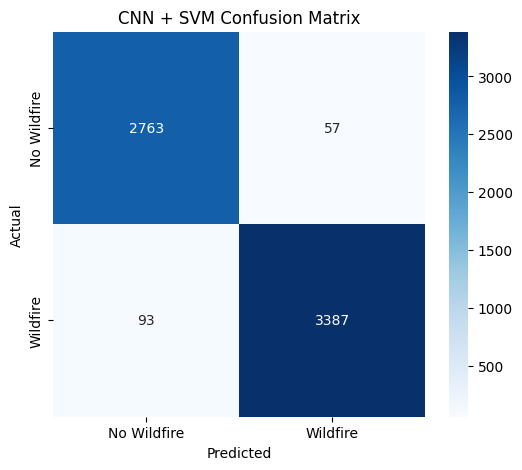

In [63]:
y_pred = cnn_svm.predict(X_test_cnn)

cm = confusion_matrix(
    y_test_cnn,
    y_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Wildfire', 'Wildfire'],
    yticklabels=['No Wildfire', 'Wildfire']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title('CNN + SVM Confusion Matrix')

plt.show()